# APS360 — HAB phytoplankton classification
Reproduces all steps so far on the **local runtime** (Colab → Connect → *Connect to a local runtime*).
Code lives in `code\*.py`; `RERUN = True` re-runs steps 1–4 (~5 min), `RERUN_TRAIN = True` retrains the networks (~110 min); `False` only loads saved results.

## 0. Setup

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT_DIR = Path(r"C:\Users\withh\OneDrive\桌面\APS 360 Project")
assert os.name == "nt" and PROJECT_DIR.is_dir(), "Connect Colab to the local runtime first."
os.chdir(PROJECT_DIR / "code"); sys.path.insert(0, os.getcwd())
os.environ["PYTHONUTF8"] = "1"                 # scripts print paths with Chinese characters
import config as C

RERUN = False                                  # True = recompute everything
def run(*cmd, rerun=None):                     # separate process: needed for multiprocessing on Windows
    if RERUN if rerun is None else rerun:
        r = subprocess.run([sys.executable, "-u", *cmd], capture_output=True, text=True, encoding="utf-8")
        print(r.stdout[-5000:], r.stderr[-3000:])
        r.check_returncode()
FIG = C.FIG_DIR

import torch
print(sys.version.split()[0], "| CUDA:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

3.14.7 | CUDA: True NVIDIA GeForce RTX 4060


## 1. Data audit — counts, corrupted files, duplicates, image sizes

In [2]:
run("00_audit_data.py")
print((PROJECT_DIR / "audit_out" / "summary.txt").read_text(encoding="utf-8"))

DATA AUDIT SUMMARY
OK 2016-19 images                          63,074   (expected 63,074)
OK 2016-19 classes                             50   (expected 50)
OK 2021 labelled images                    57,207   (expected 57,207)
OK 2021 unclassifiable images              94,028   (expected 94,028)
OK retained classes (>=100, no Beads)          38   (expected 38)
OK 2021 images in retained classes         56,890   (expected 56,890)

Label mapping draft: exact=48, none (check by hand)=2
Retained classes missing from 2021: Prorocentrum_cordatum

Unreadable files: 0   Non-grayscale: 0
Duplicate groups: 0  (cross-year: 0, conflicting labels: 0)

Image size, retained 2016-19 classes (longest side):
  p5=88  p25=104  p50=136  p75=208  p95=480  p99=784
  share with longest side <= 64/128/160/224 px: 0% / 47% / 61% / 78%

Outputs written to: C:\Users\withh\OneDrive\桌面\APS 360 Project\audit_out



## 2. Label mapping, HAB labels, splits (seed 42, 85/15, train cap 1,500/class)

In [3]:
run("01_prepare_splits.py")
print((C.PREP_DIR / "prep_summary.txt").read_text(encoding="utf-8"))
lm = pd.read_csv(C.PREP_DIR / "label_mapping.csv")
lm[lm["note"] != "exact folder-name match"]          # classes that are not a plain match

PREP SUMMARY (steps 1-3)
Retained classes: 38  (HAB: 8)
Train (capped):    27,033   [proposal: 27,033]  HAB images: 8,063
Validation:         9,348   HAB images: 4,473
Test 2021:         56,890   [proposal: 56,890]  HAB images: 6,723
OOD 2021:          94,345   (labelled other: 317, unclassifiable: 94,028)

Retained classes with < 20 test images (report metrics as unreliable / n/a):
  Chroococcus_small (2), Cymbomonas_tetramitiformis (4), Dinophysis_acuminata (17), Euglenophyceae (18), Prorocentrum_cordatum (0)

Train images fitting 96x256 without downscaling: 71%

Classes whose median size changed >25% between years (n_2021 >= 20): 9
  Chaetoceros_sp                       width x0.82  height x0.7
  Chaetoceros_sp_single                width x0.91  height x0.76
  Dinophyceae                          width x0.76  height x0.82
  Dolichospermum-Anabaenopsis          width x1.05  height x0.73
  Gymnodinium_like                     width x0.85  height x0.78
  Nodularia_spumigena            

,name_2016_2019,name_2021,class_id,hab,n_2016_2019,n_2021,note
0,Amylax_triacantha,Amylax_triacantha,NaN,NaN,19,3,exact folder-name match; dropped (<100 images ...
2,Aphanothece_paralleliformis,Aphanothece_paralleliformis,NaN,NaN,29,9,exact folder-name match; dropped (<100 images ...
3,Beads,NaN,NaN,NaN,125,0,absent from 2021; dropped (non-plankton)
5,Ceratoneis_closterium,Ceratoneis_closterium,NaN,NaN,45,75,exact folder-name match; dropped (<100 images ...
8,Chlorococcales,Chlorococcales,NaN,NaN,95,45,exact folder-name match; dropped (<100 images ...
22,Gonyaulax_verior,Gonyaulax_verior,NaN,NaN,22,1,exact folder-name match; dropped (<100 images ...
23,Gymnodiniales,Gymnodiniales,NaN,NaN,69,38,exact folder-name match; dropped (<100 images ...
28,Katablepharis_remigera,Katablepharis_remigera,NaN,NaN,54,4,exact folder-name match; dropped (<100 images ...
29,Licmophora_sp,Licmophora_sp,NaN,NaN,74,78,exact folder-name match; dropped (<100 images ...
30,Melosira_arctica,Melosira_arctica,NaN,NaN,43,58,exact folder-name match; dropped (<100 images ...


## 3. Segmentation, features and 96×256 cache

In [4]:
run("02_build_cache.py")
stats = json.load(open(C.CACHE_DIR / "cache_stats.json"))
names = stats["feature_names"]
display(pd.DataFrame({s: stats[s] for s in C.SPLITS}).T)
print("Features:", len(names))

,n,seg_fail,shrunk_frac
train,27033.0,0.0,0.2928
val,9348.0,0.0,0.3516
test,56890.0,0.0,0.1070
ood,94345.0,0.0,0.0164


Features: 27


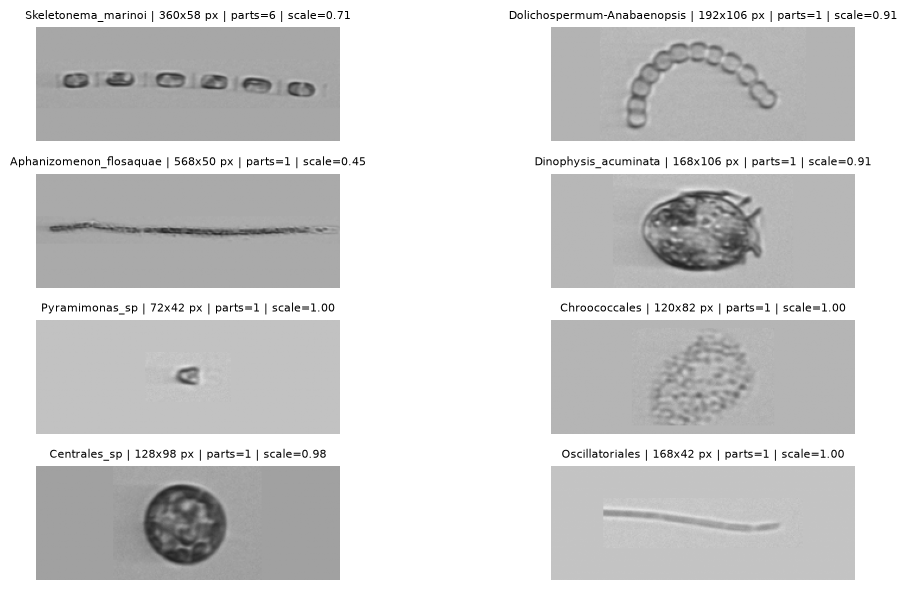

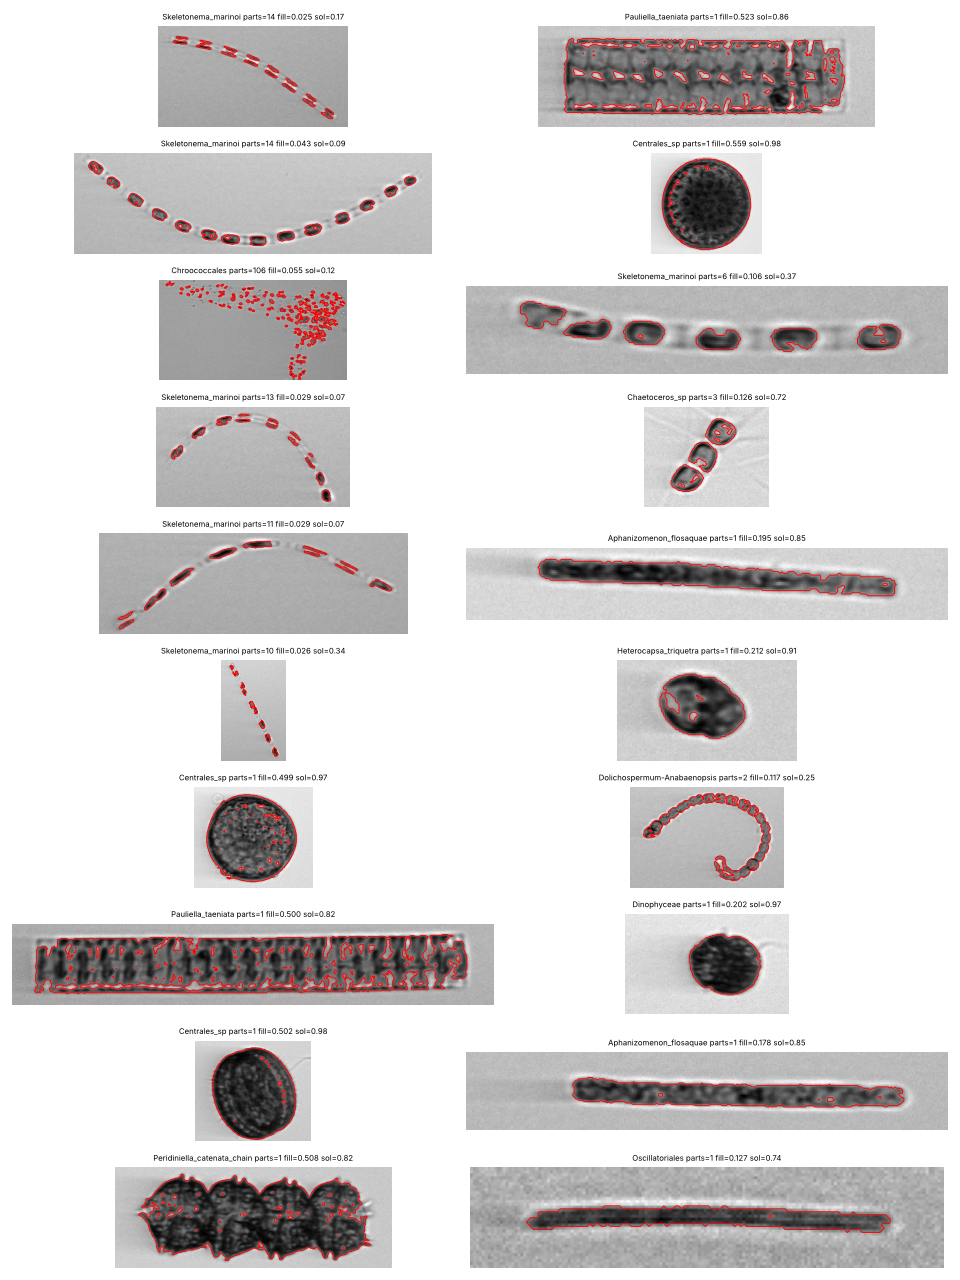

In [5]:
imgs = np.load(C.CACHE_DIR / "train_images.npy", mmap_mode="r")
feats = np.load(C.CACHE_DIR / "train_feats.npy")
train = pd.read_csv(C.PREP_DIR / "train.csv")
show = ["Skeletonema_marinoi", "Dolichospermum-Anabaenopsis", "Aphanizomenon_flosaquae", "Dinophysis_acuminata",
        "Pyramimonas_sp", "Chroococcales", "Centrales_sp", "Oscillatoriales"]
fig, axes = plt.subplots(4, 2, figsize=(12, 6))
for ax, c in zip(axes.ravel(), show):
    i = train.index[train["class"] == c][0]
    f = dict(zip(names, feats[i]))
    ax.imshow(imgs[i], cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"{c} | {int(f['img_w'])}x{int(f['img_h'])} px | parts={int(f['n_parts'])} | scale={f['scale']:.2f}", fontsize=8)
plt.tight_layout(); plt.show()
display(Image(str(FIG / "segmentation_check.png"), width=900))   # red = measured organism

## 4. Baseline B1 — random forest

In [6]:
run("03_random_forest.py")
rf = json.load(open(C.RF_DIR / "rf_results.json"))
print(f"n_trees = {rf['n_trees']} (val macro-F1 grid {rf['grid_val_macro_f1']}) | tau = {rf['tau']}")
keys = ["accuracy", "macro_f1", "weighted_f1", "hab_recall", "hab_precision", "coverage", "accuracy_confident"]
display(pd.DataFrame({"val": rf["val"], "test_2021": rf["test_2021"]}).loc[keys])
print(f"False HAB alerts on OOD: {rf['ood_hab_alert_rate']:.2%} | labelled uncertain: {rf['ood_uncertain_rate']:.1%}")
pd.read_csv(C.RF_DIR / "per_class_test.csv")         # per-class metrics with n_train / n_test

n_trees = 200 (val macro-F1 grid {'100': 0.7835, '200': 0.7874, '350': 0.7865, '500': 0.7841}) | tau = 0.35


,val,test_2021
accuracy,0.8909,0.6656
macro_f1,0.7874,0.4783
weighted_f1,0.8934,0.6786
hab_recall,0.9622,0.9301
hab_precision,0.9892,0.9140
coverage,0.9506,0.9003
accuracy_confident,0.9157,0.7070


False HAB alerts on OOD: 0.38% | labelled uncertain: 13.5%


,class,hab,n_train,n_test,precision,recall,f1
0,Cryptophyceae-Teleaulax,0,1500,16952,0.903,0.579,0.705
1,Pyramimonas_sp,0,1040,8422,0.614,0.951,0.746
2,Skeletonema_marinoi,0,1500,7402,0.983,0.689,0.810
3,Oscillatoriales,1,1500,3893,0.974,0.956,0.965
4,Heterocapsa_rotundata,0,522,2609,0.514,0.645,0.572
5,Heterocapsa_triquetra,0,1500,2267,0.776,0.717,0.746
6,Thalassiosira_levanderi,0,1500,2008,0.572,0.526,0.548
7,Aphanizomenon_flosaquae,1,1500,1849,0.793,0.829,0.811
8,Eutreptiella_sp,0,1500,1678,0.337,0.675,0.450
9,Dinophyceae,0,1218,1562,0.521,0.181,0.268


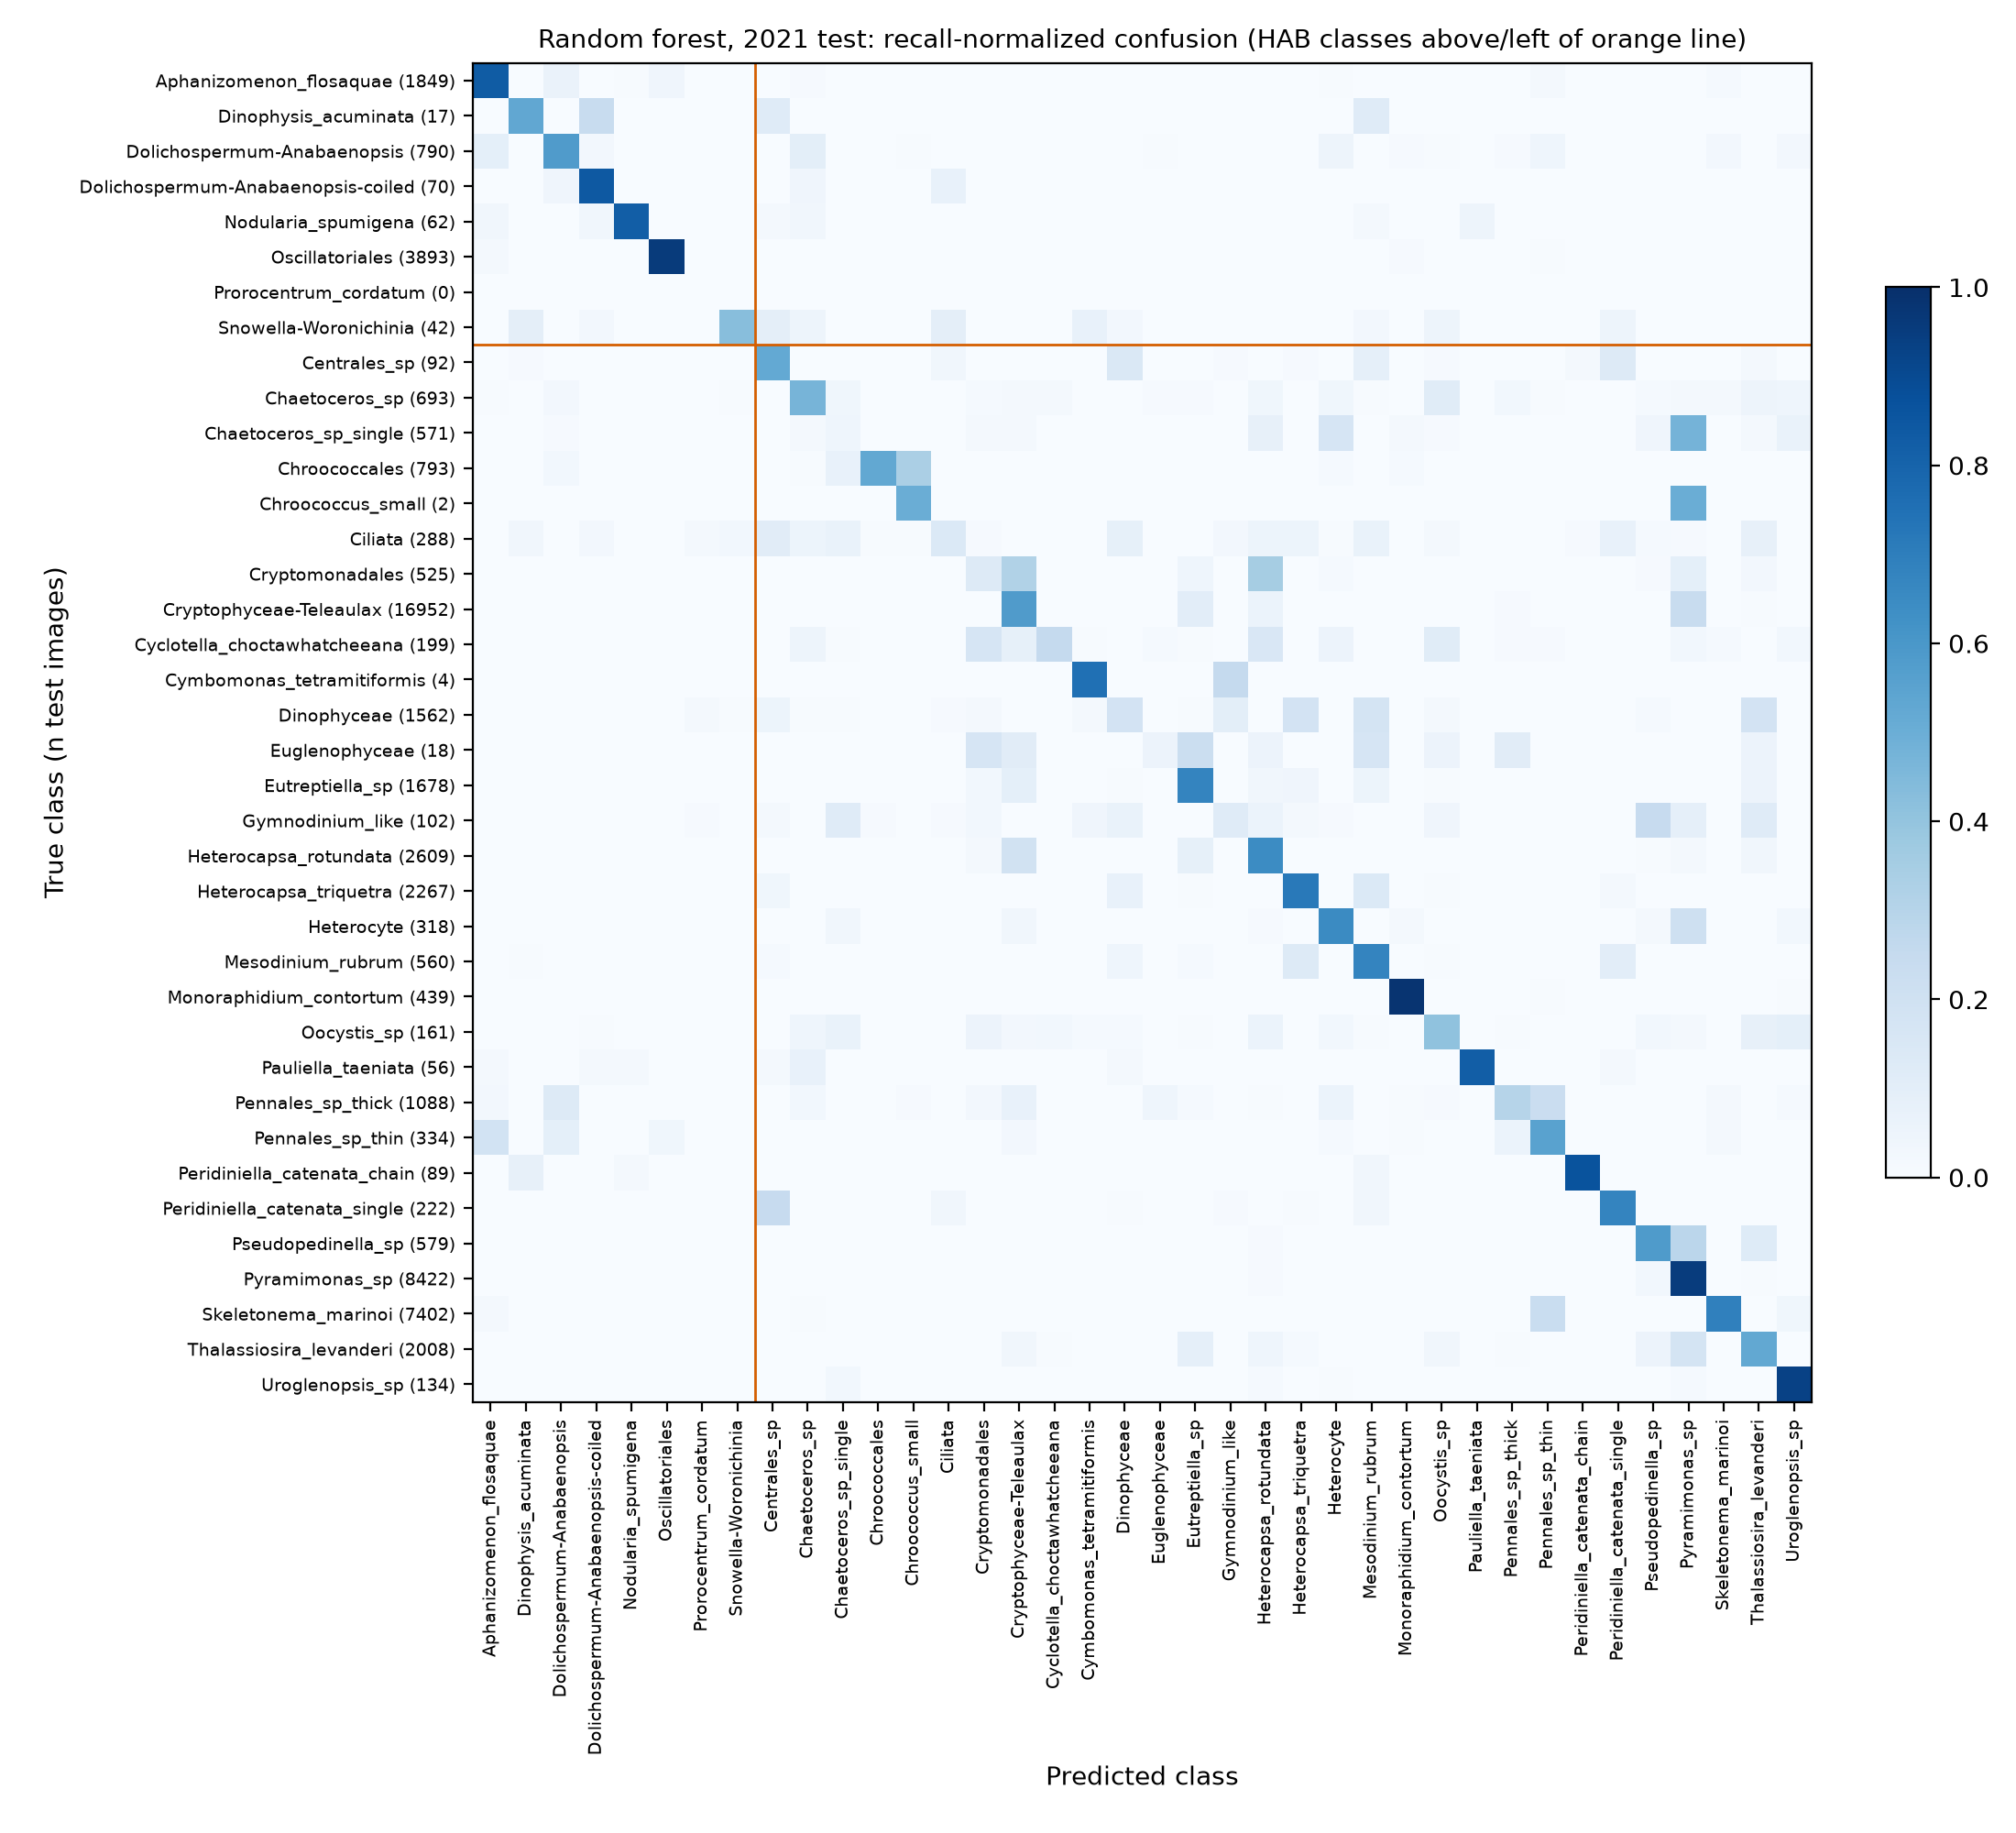

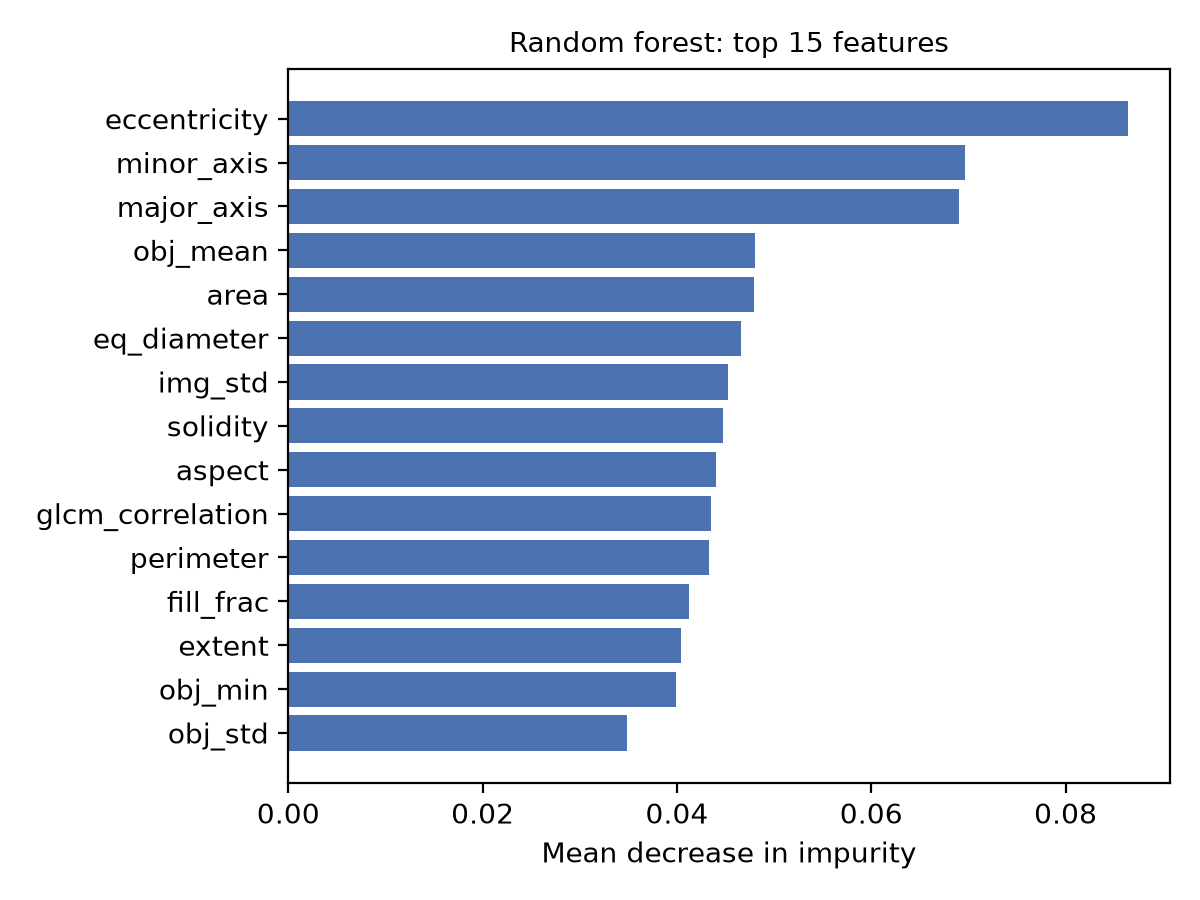

In [7]:
display(Image(str(FIG / "rf_confusion_test.png"), width=900))
display(Image(str(FIG / "rf_feature_importance.png"), width=500))

## 5. Primary model HAB-Net (M: 40 epochs; M80 / M80w1: 80 epochs with HAB weight w_H = 3 / 1) and baseline B2 (ResNet-18, ImageNet, fine-tuned)

In [8]:
from models import HABNet, n_params
net, rows = HABNet().eval(), []
blocks = [(f"image stage {i + 1}", m) for i, m in enumerate(net.image[:4])] + [("image GAP", net.image[4]),
         ("morph MLP", net.morph), ("fusion", net.fuse), ("species head", net.species), ("HAB head", net.hab)]
for n, m in blocks:
    m.register_forward_hook(lambda m, i, o, n=n: rows.append((n, tuple(o.shape[1:]), n_params(m))))
net(torch.zeros(2, 1, C.CANVAS_H, C.CANVAS_W), torch.zeros(2, len(C.MORPH_FEATURES)))
print(f"HAB-Net: input 1x{C.CANVAS_H}x{C.CANVAS_W} + {len(C.MORPH_FEATURES)} morphology features | {n_params(net):,} parameters")
pd.DataFrame(rows, columns=["block", "output shape", "parameters"])

HAB-Net: input 1x96x256 + 8 morphology features | 1,216,135 parameters


,block,output shape,parameters
0,image stage 1,"(32, 48, 128)",9632
1,image stage 2,"(64, 24, 64)",55552
2,image stage 3,"(128, 12, 32)",221696
3,image stage 4,"(256, 6, 16)",885760
4,image GAP,"(256, 1, 1)",0
5,morph MLP,"(32,)",1472
6,fusion,"(128,)",36992
7,species head,"(38,)",4902
8,HAB head,"(1,)",129


M: 1,216,135 params | best epoch 40/40 | 20.9 min | tau 0.8195 | config {'model': 'habnet', 'morph': True, 'hab_head': True, 'lr': 0.001, 'w_hab': 3.0, 'lam': 0.5}


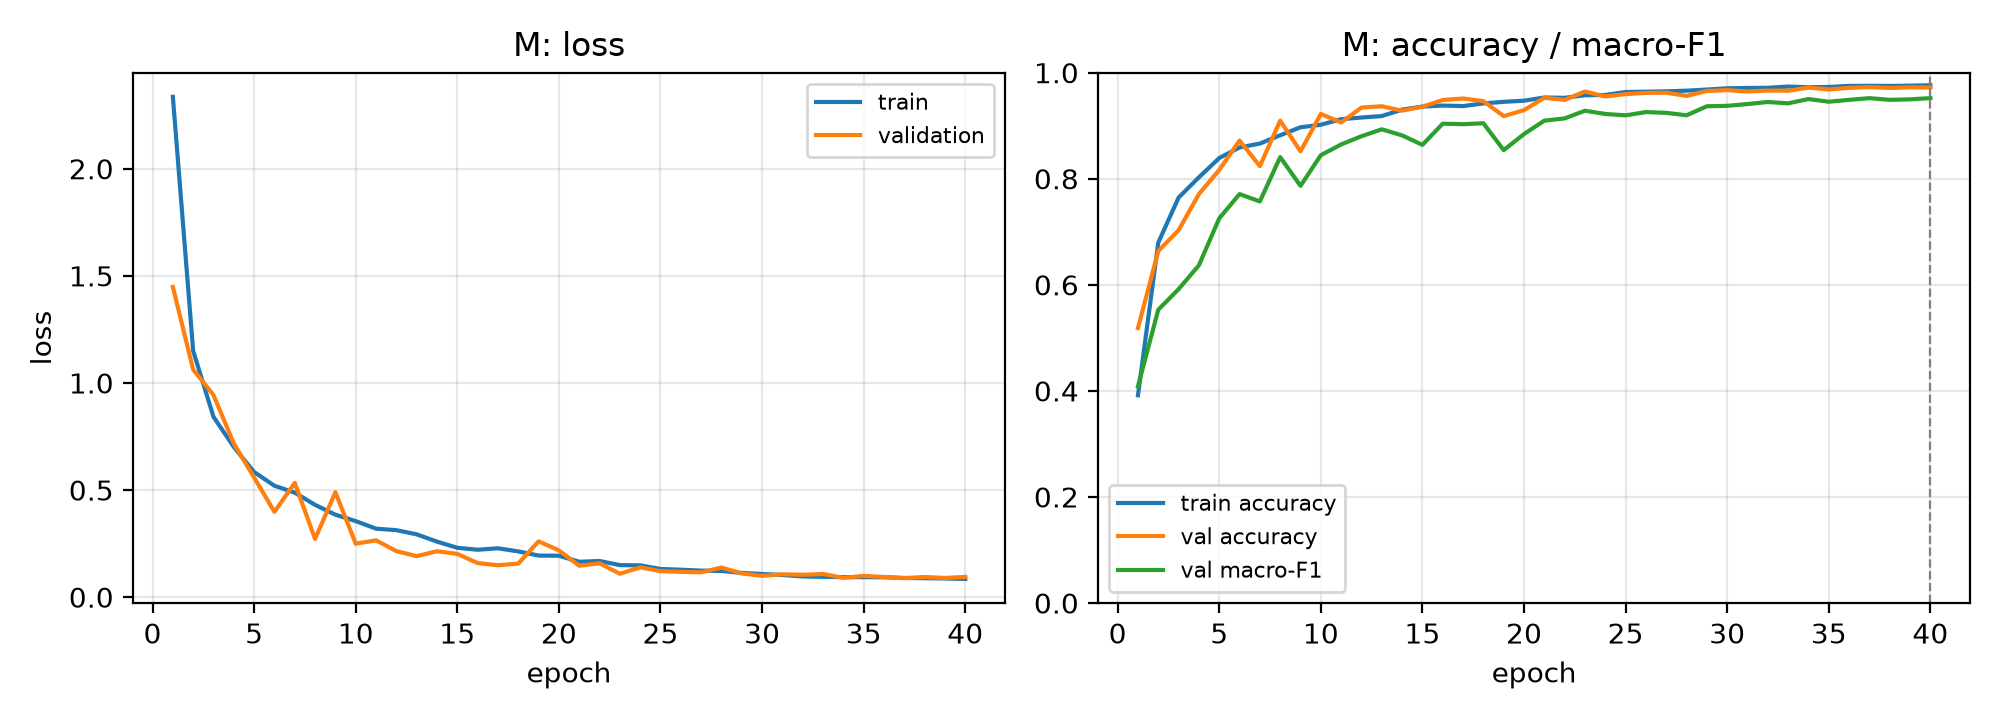

B2: 11,196,006 params | best epoch 22/30 | 9.2 min | tau 0.9762 | config {'model': 'resnet18', 'morph': False, 'hab_head': False, 'lr': 0.0003}


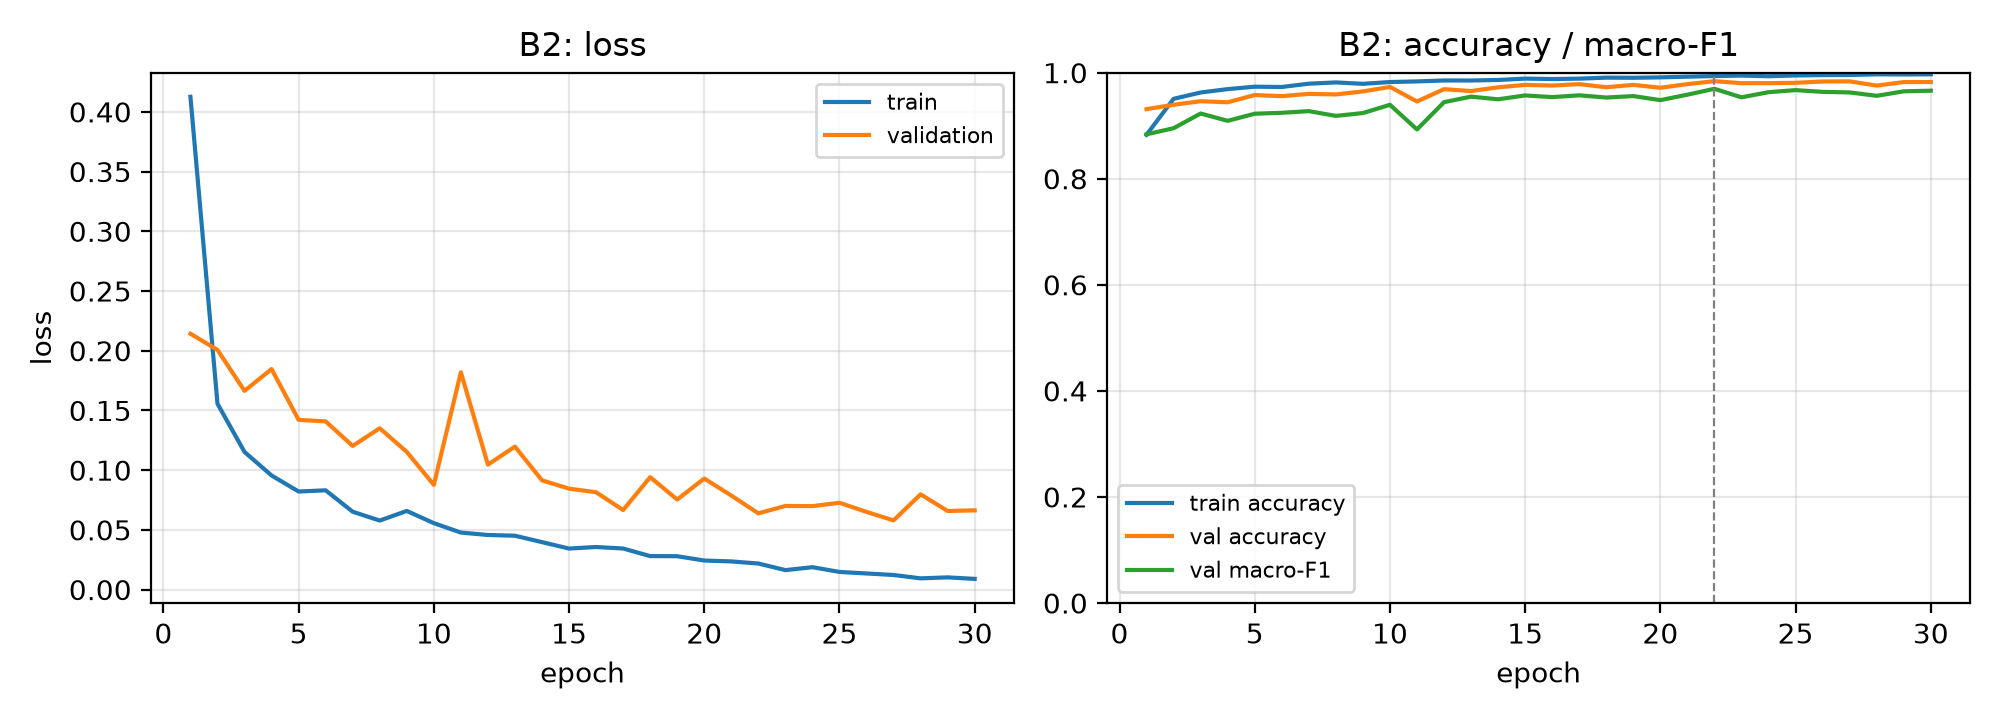

M80: 1,216,135 params | best epoch 71/80 | 39.8 min | tau 0.9045 | config {'model': 'habnet', 'morph': True, 'hab_head': True, 'lr': 0.001, 'w_hab': 3.0, 'lam': 0.5, 'epochs': 80, 'patience': 15}


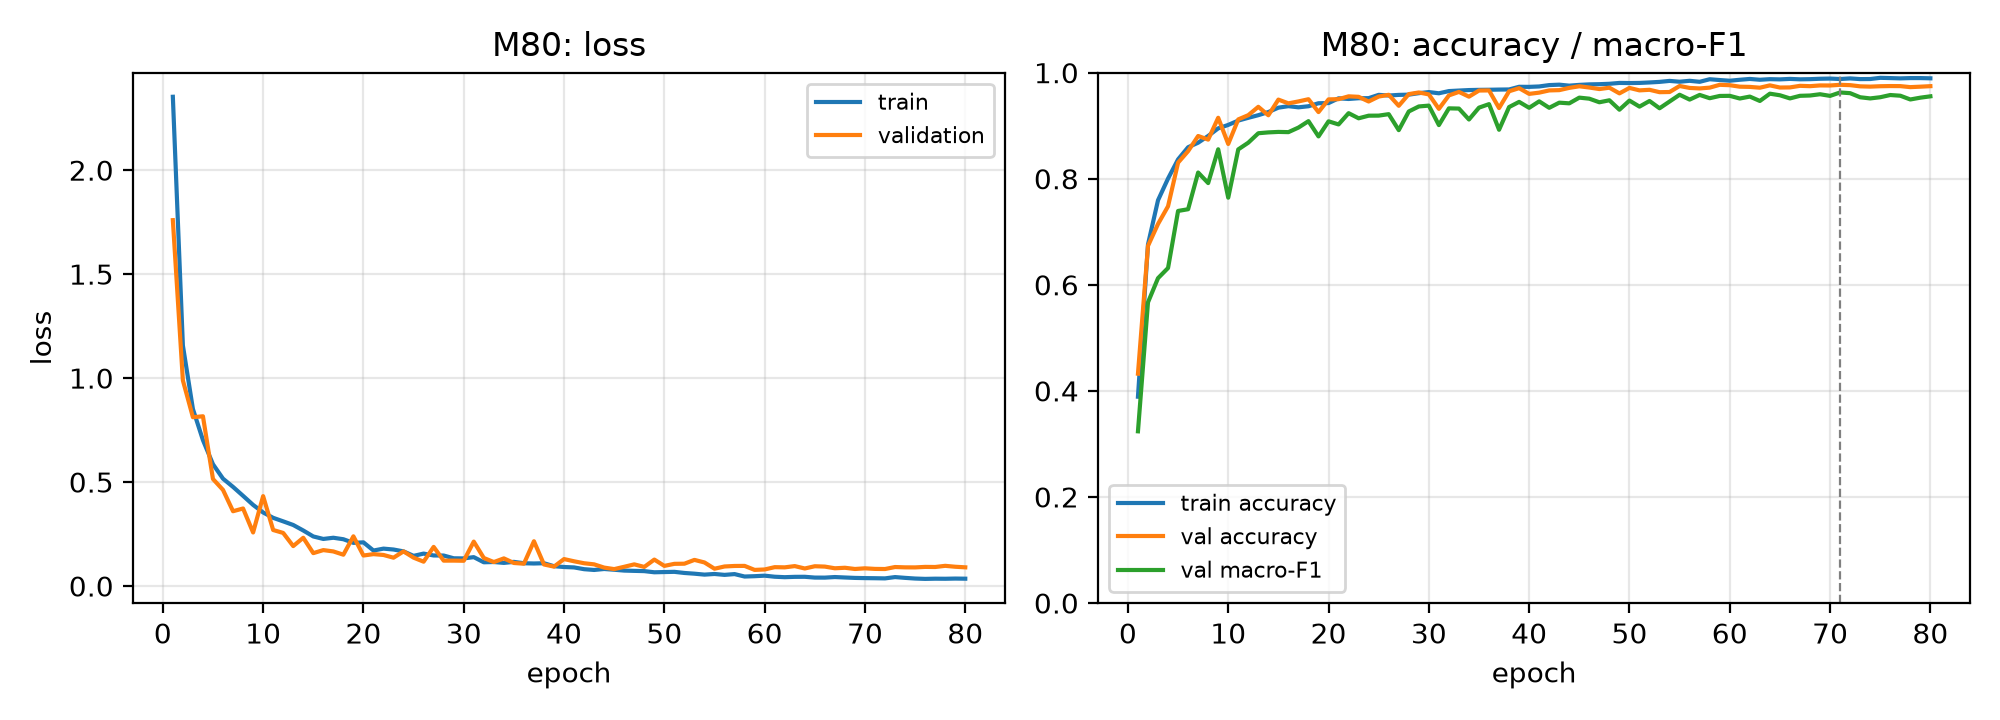

M80w1: 1,216,135 params | best epoch 68/80 | 40.2 min | tau 0.9075 | config {'model': 'habnet', 'morph': True, 'hab_head': True, 'lr': 0.001, 'w_hab': 1.0, 'lam': 0.5, 'epochs': 80, 'patience': 15}


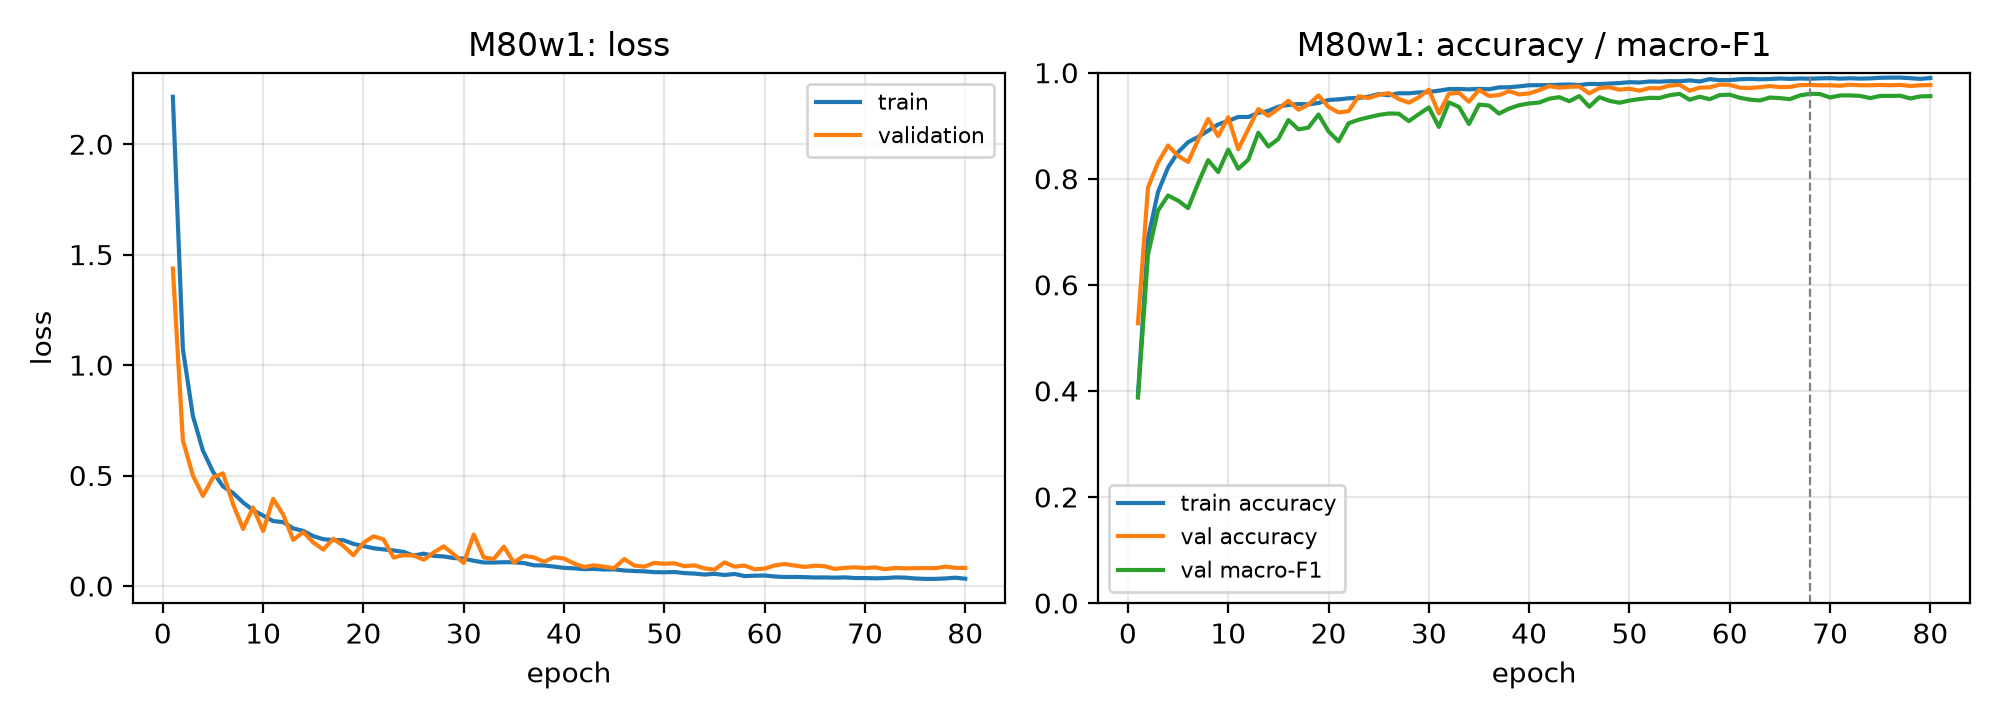

In [9]:
RERUN_TRAIN = False                            # True = retrain M, B2, M80, M80w1 (~110 min on the RTX 4060)
run("04_train.py", "--runs", "M", "B2", "M80", "M80w1", rerun=RERUN_TRAIN)
for k in [k for k in ("M", "B2", "M80", "M80w1") if (C.RUNS_DIR / k / "results.json").exists()]:
    r = json.load(open(C.RUNS_DIR / k / "results.json"))
    print(f"{k}: {r['params']:,} params | best epoch {r['best_epoch']}/{r['epochs_trained']} | "
          f"{r['train_time_s'] / 60:.1f} min | tau {r['tau']} | config {r['config']}")
    display(Image(str(FIG / f"learning_curves_{k}.png"), width=850))

## 6. Comparison on the 2021 test set. Selected HAB-Net = best validation macro-F1 with validation HAB recall ≥ 0.95

Selected HAB-Net: HAB-Net 80ep wH=3 (M80)


,metric,RF (B1),ResNet-18 (B2),HAB-Net 40ep (M),HAB-Net 80ep wH=3 (M80),HAB-Net 80ep wH=1 (M80w1)
0,Val macro-F1,0.7874,9.696000e-01,9.520000e-01,9.627000e-01,9.602000e-01
1,Test accuracy,0.6656,8.855000e-01,8.310000e-01,8.716000e-01,8.700000e-01
2,Test macro-F1,0.4783,7.712000e-01,7.003000e-01,7.411000e-01,7.302000e-01
3,Test weighted-F1,0.6786,8.881000e-01,8.372000e-01,8.758000e-01,8.748000e-01
4,Test HAB recall,0.9301,9.893000e-01,9.647000e-01,9.537000e-01,9.610000e-01
5,Test HAB precision,0.914,9.792000e-01,9.863000e-01,9.915000e-01,9.875000e-01
6,Test coverage (conf >= tau),0.9003,7.673000e-01,7.761000e-01,7.947000e-01,8.005000e-01
7,Test accuracy when confident,0.707,9.693000e-01,9.235000e-01,9.466000e-01,9.449000e-01
8,OOD false HAB alerts,0.0038,2.300000e-03,7.500000e-03,4.500000e-03,6.800000e-03
9,Parameters,-,1.119601e+07,1.216135e+06,1.216135e+06,1.216135e+06


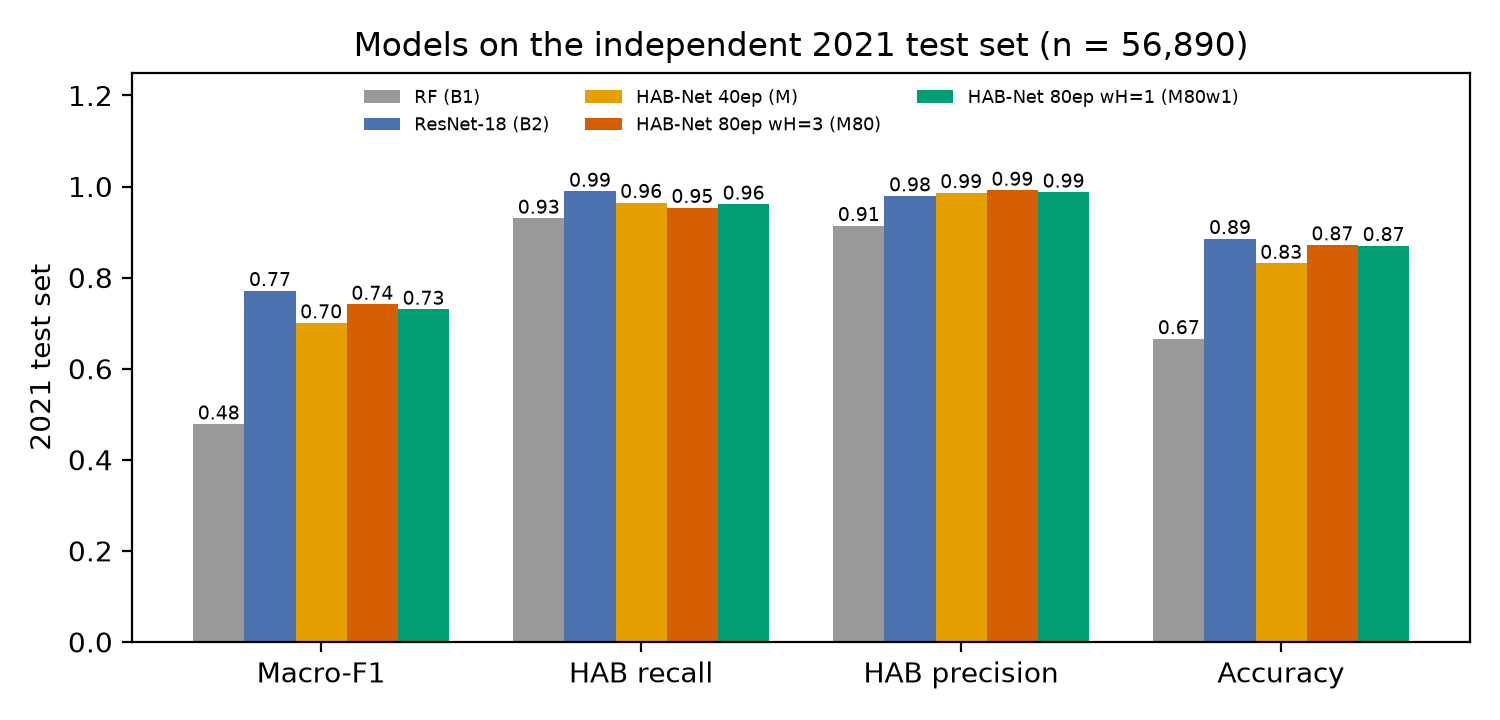

,class,hab,n_train,n_test,F1 RF (B1),F1 ResNet-18 (B2),F1 HAB-Net 40ep (M),F1 HAB-Net 80ep wH=3 (M80),F1 HAB-Net 80ep wH=1 (M80w1)
0,Cryptophyceae-Teleaulax,0,1500,16952,0.705,0.898,0.842,0.889,0.895
1,Pyramimonas_sp,0,1040,8422,0.746,0.850,0.825,0.864,0.874
2,Skeletonema_marinoi,0,1500,7402,0.810,0.969,0.964,0.972,0.967
3,Oscillatoriales,1,1500,3893,0.965,0.998,0.991,0.984,0.985
4,Heterocapsa_rotundata,0,522,2609,0.572,0.921,0.806,0.912,0.921
5,Heterocapsa_triquetra,0,1500,2267,0.746,0.949,0.890,0.945,0.935
6,Thalassiosira_levanderi,0,1500,2008,0.548,0.846,0.744,0.816,0.807
7,Aphanizomenon_flosaquae,1,1500,1849,0.811,0.956,0.948,0.958,0.946
8,Eutreptiella_sp,0,1500,1678,0.450,0.879,0.732,0.735,0.719
9,Dinophyceae,0,1218,1562,0.268,0.683,0.661,0.781,0.740


In [10]:
run("05_compare.py", rerun=RERUN or RERUN_TRAIN)
print("Selected HAB-Net:", (C.OUT_ROOT / "selected_model.txt").read_text(encoding="utf-8").strip())
display(pd.read_csv(C.OUT_ROOT / "comparison.csv"))
display(Image(str(FIG / "model_comparison.png"), width=750))
pd.read_csv(C.OUT_ROOT / "per_class_comparison.csv")      # per-class F1 with n_train / n_test

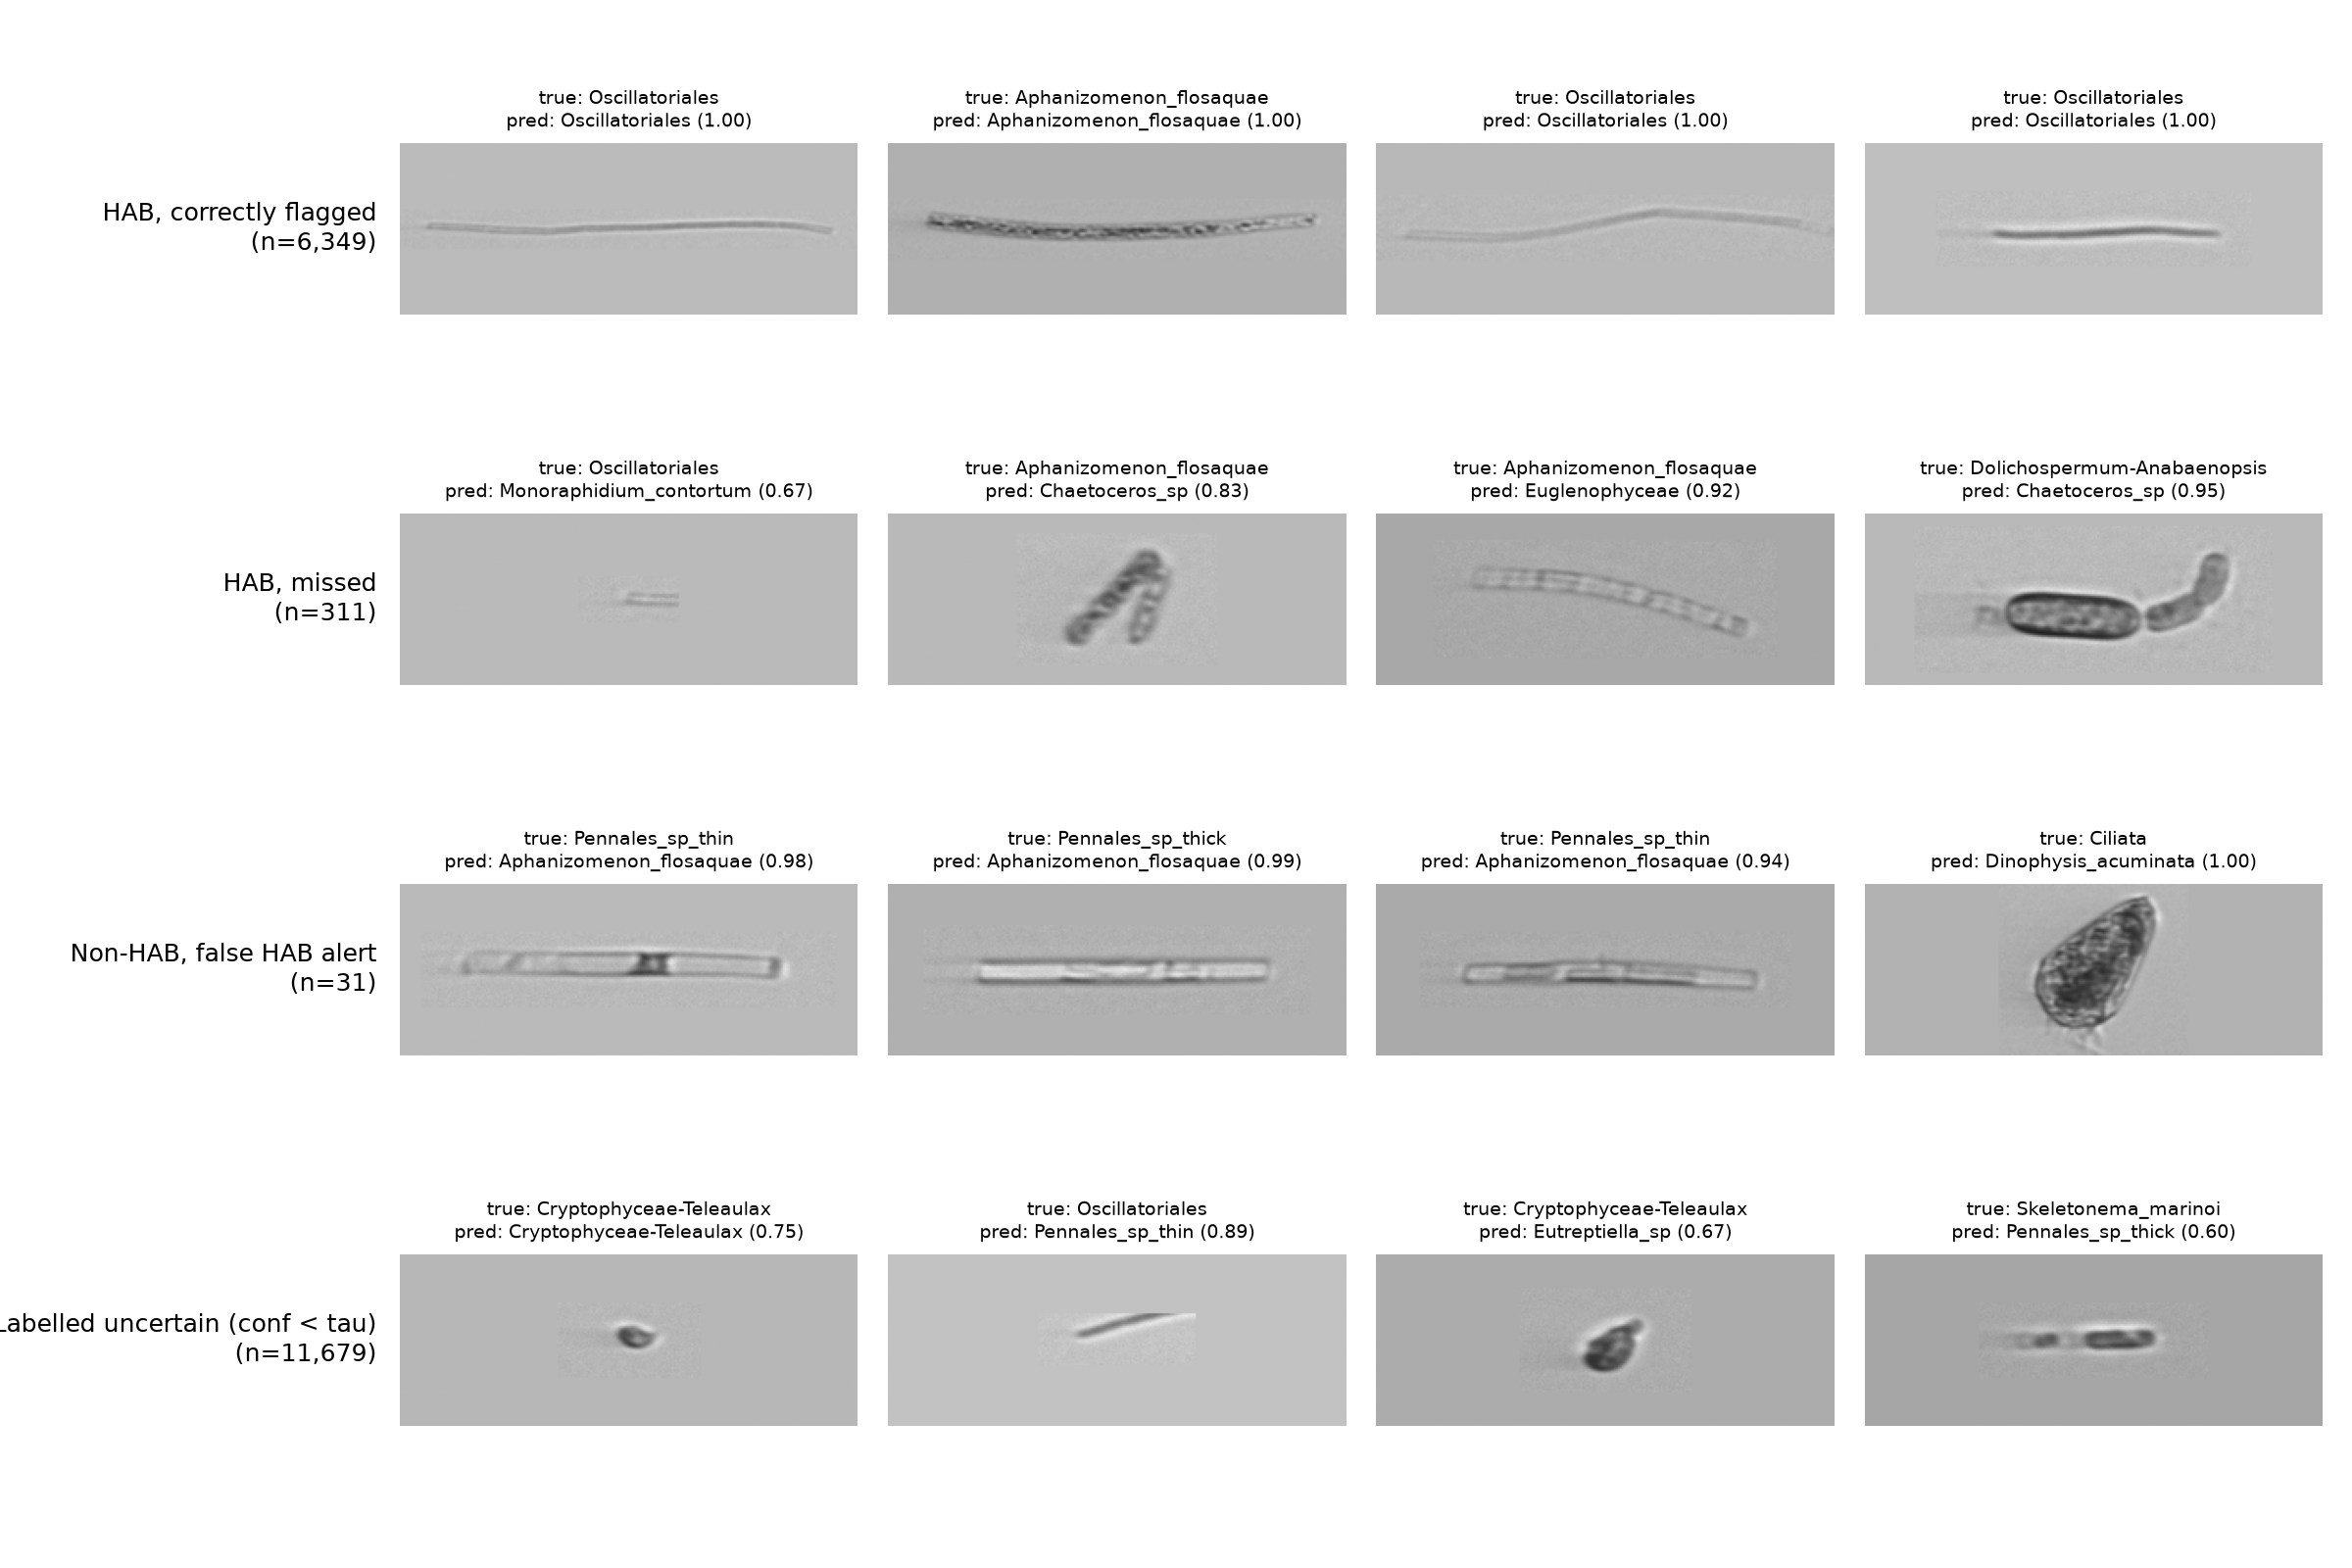

In [11]:
display(Image(str(FIG / "habnet_examples.png"), width=950))   # qualitative: hits, misses, false alerts, uncertain